SHAP values shape: (9043, 5)
Base value (log-odds): -2.0359
Explanation of first test customer:
age  Value = 40  SHAP = -0.1982
balance  Value = 640  SHAP = 0.0215
campaign  Value = 2  SHAP = -0.0233
pdays  Value = -1  SHAP = -0.2029
previous  Value = 0  SHAP = -0.0283
Base value + sum of SHAP values: -2.4671
Model output (log-odds): -2.4671
Mean absolute SHAP value of each feature:
pdays = 0.29
age = 0.2344
balance = 0.207
campaign = 0.1392
previous = 0.0372


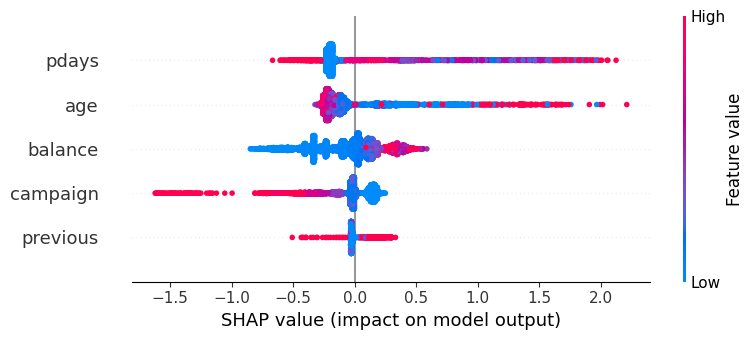

In [1]:
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

df = pd.read_csv("Datasets/bank-full.csv", sep=";")
X = df[["age", "balance", "campaign", "pdays", "previous"]]
y = (df["y"] == "yes").astype(int)
names = list(X.columns)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42)
model.fit(Xtr, ytr)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(Xte)
base = float(explainer.expected_value)

print("SHAP values shape:", shap_values.shape)
print("Base value (log-odds):", round(base, 4))

print("Explanation of first test customer:")
for i in range(len(names)):
    print(names[i], " Value =", Xte.iloc[0, i], " SHAP =", round(float(shap_values[0][i]), 4))
print("Base value + sum of SHAP values:", round(base + float(shap_values[0].sum()), 4))

margin = model.predict(Xte.iloc[:1], output_margin=True)[0]
print("Model output (log-odds):", round(float(margin), 4))

importance = np.abs(shap_values).mean(axis=0)
print("Mean absolute SHAP value of each feature:")
for i in np.argsort(importance)[::-1]:
    print(names[i], "=", round(float(importance[i]), 4))

shap.summary_plot(shap_values, Xte)
